# 03 · Pregunta 2a: afinidades entre películas

**Responsable:** Integrante C · **Plan:** ver `PLAN.md`

Si a un usuario le gusta una película (rating ≥ 4), ¿qué otras tienden a gustarle?

## Preparación

In [2]:
from pathlib import Path
import sys

# Busca la raíz del repo (la carpeta que contiene src/) sin importar desde dónde se abra el notebook.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import contratos, rutas
from src import limpieza, afinidades_peliculas

## Datos

In [3]:
movies, ratings = limpieza.datos_limpios()
contratos.verificar_esquema(movies, "movies")
contratos.verificar_esquema(ratings, "ratings")
print(movies.shape, ratings.shape)

(300, 23) (8492, 5)


c:\Users\jonathan\Desktop\Proyecto\movielens-proyecto-integrador\src\limpieza.py:66: UserWarning: cargar_movies() es un DUMMY: devuelve datos inventados con el esquema del contrato.
  return movies_limpias(cargar_movies()), ratings_limpias(cargar_ratings())
c:\Users\jonathan\Desktop\Proyecto\movielens-proyecto-integrador\src\limpieza.py:66: UserWarning: movies_limpias() es un DUMMY: devuelve datos inventados con el esquema del contrato.
  return movies_limpias(cargar_movies()), ratings_limpias(cargar_ratings())
c:\Users\jonathan\Desktop\Proyecto\movielens-proyecto-integrador\src\limpieza.py:66: UserWarning: cargar_ratings() es un DUMMY: devuelve datos inventados con el esquema del contrato.
  return movies_limpias(cargar_movies()), ratings_limpias(cargar_ratings())
c:\Users\jonathan\Desktop\Proyecto\movielens-proyecto-integrador\src\limpieza.py:66: UserWarning: ratings_limpias() es un DUMMY: devuelve datos inventados con el esquema del contrato.
  return movies_limpias(cargar_movies())

## 1. Matriz de gustos

1 = rating ≥ 4, 0 = rating < 4, NaN = no la vio. Explicar por qué un NaN no es un 0 y por qué se usan solo las películas con n ≥ 100.

In [4]:
gustos = afinidades_peliculas.matriz_gustos(ratings, min_n=100)
contratos.verificar_matriz(gustos, "gusto")
gustos.shape

(120, 6)

## 2. Sesgo por usuario

In [5]:
# TODO: % de ratings >= 4 por usuario (describe); qué implica para la definición de 'gustar'
porcentaje_gustos =(
    ratings.assign(gusto=ratings["rating"] >= 4)
    .groupby("userId")["gusto"]
    .mean()*100
    )

porcentaje_gustos.head(5)

userId
1      42.500000
10     52.252252
100    52.500000
101    50.000000
102    44.155844
Name: gusto, dtype: float64

In [6]:
porcentaje_gustos.describe()

count    120.000000
mean      47.842299
std        7.272692
min       31.578947
25%       43.322981
50%       48.145604
75%       51.112998
max       70.000000
Name: gusto, dtype: float64

In [7]:
from IPython.display import display, Markdown

estadisticas = porcentaje_gustos.describe()

display(Markdown(f"""
### Sesgo por usuario

Se analizaron **{int(estadisticas['count'])} usuarios**.

El porcentaje promedio de calificaciones iguales o superiores a 4 fue de
**{estadisticas['mean']:.2f}%**, con una desviación estándar de
**{estadisticas['std']:.2f} puntos porcentuales**.

Los porcentajes van desde **{estadisticas['min']:.2f}%**
hasta **{estadisticas['max']:.2f}%**.

Esto muestra que existen diferencias entre los usuarios al momento de
calificar películas. Por lo tanto, definir que una película gustó cuando
su calificación fue mayor o igual a 4 puede representar distintos niveles
de satisfacción dependiendo del usuario.
"""))


### Sesgo por usuario

Se analizaron **120 usuarios**.

El porcentaje promedio de calificaciones iguales o superiores a 4 fue de
**47.84%**, con una desviación estándar de
**7.27 puntos porcentuales**.

Los porcentajes van desde **31.58%**
hasta **70.00%**.

Esto muestra que existen diferencias entre los usuarios al momento de
calificar películas. Por lo tanto, definir que una película gustó cuando
su calificación fue mayor o igual a 4 puede representar distintos niveles
de satisfacción dependiendo del usuario.


## 3. Correlación entre películas

In [ ]:
# TODO: corr con min_periods; cuántos pares quedan con correlación definida
correlaciones = gustos.corr(min_periods=20)
correlaciones_titulos = correlaciones.rename(
    index=movies.set_index("movieId")["title"],
    columns=movies.set_index("movieId")["title"]
)

display(correlaciones_titulos.iloc[:5, :5])

# Contar pares con correlación definida (sin diagonal ni duplicados)
n_pares_definidos = correlaciones.where(
    np.triu(np.ones(correlaciones.shape), k=1).astype(bool)
).stack().count()

print("Dimensiones de la matriz:", correlaciones.shape)
print("Pares con correlación definida:", n_pares_definidos)

movieId,Película 187 (2009),Película 200 (1979),Película 018 (1965),Película 036 (1972),Película 077 (2003),Película 137 (1950)
movieId,,,,,,
Película 187 (2009),1.000000,-0.247159,-0.047888,-0.037268,0.026724,0.002532
Película 200 (1979),-0.247159,1.000000,-0.010190,-0.023053,-0.088302,-0.063888
Película 018 (1965),-0.047888,-0.010190,1.000000,0.036976,-0.050812,-0.063493
Película 036 (1972),-0.037268,-0.023053,0.036976,1.000000,-0.026324,0.014862
Película 077 (2003),0.026724,-0.088302,-0.050812,-0.026324,1.000000,0.106455
Película 137 (1950),0.002532,-0.063888,-0.063493,0.014862,0.106455,1.000000


Dimensiones de la matriz: (6, 6)
Pares con correlación definida: 15


## 4. Pares con mayor afinidad

In [9]:
# TODO: triángulo superior de la matriz, stack y ordenar; mostrar los títulos

triangulo_superior = correlaciones.where(
    np.triu(np.ones(correlaciones.shape), k=1).astype(bool)
)

# Evitar nombres duplicados
triangulo_superior.index.name = "movieId_1"
triangulo_superior.columns.name = "movieId_2"

# Convertir la matriz en una tabla de parejas
pares_correlacion = triangulo_superior.stack().reset_index()

# Nombrar las columnas
pares_correlacion.columns = [
    "movieId_1",
    "movieId_2",
    "correlacion"
]

# Ordenar de mayor a menor correlación
pares_correlacion = pares_correlacion.sort_values(
    by="correlacion",
    ascending=False
)

# Incorporar los títulos de las películas
pares_correlacion = pares_correlacion.merge(
    movies[["movieId", "title"]],
    left_on="movieId_1",
    right_on="movieId",
    how="left"
).rename(columns={"title": "pelicula_1"}).drop(columns="movieId")

pares_correlacion = pares_correlacion.merge(
    movies[["movieId", "title"]],
    left_on="movieId_2",
    right_on="movieId",
    how="left"
).rename(columns={"title": "pelicula_2"}).drop(columns="movieId")

# Mostrar las 10 parejas con mayor correlación
pares_correlacion[
    ["pelicula_1", "pelicula_2", "correlacion"]
].head(10)

,pelicula_1,pelicula_2,correlacion
0,Película 077 (2003),Película 137 (1950),0.106455
1,Película 018 (1965),Película 036 (1972),0.036976
2,Película 187 (2009),Película 077 (2003),0.026724
3,Película 036 (1972),Película 137 (1950),0.014862
4,Película 187 (2009),Película 137 (1950),0.002532
5,Película 200 (1979),Película 018 (1965),-0.010190
6,Película 200 (1979),Película 036 (1972),-0.023053
7,Película 036 (1972),Película 077 (2003),-0.026324
8,Película 187 (2009),Película 036 (1972),-0.037268
9,Película 187 (2009),Película 018 (1965),-0.047888


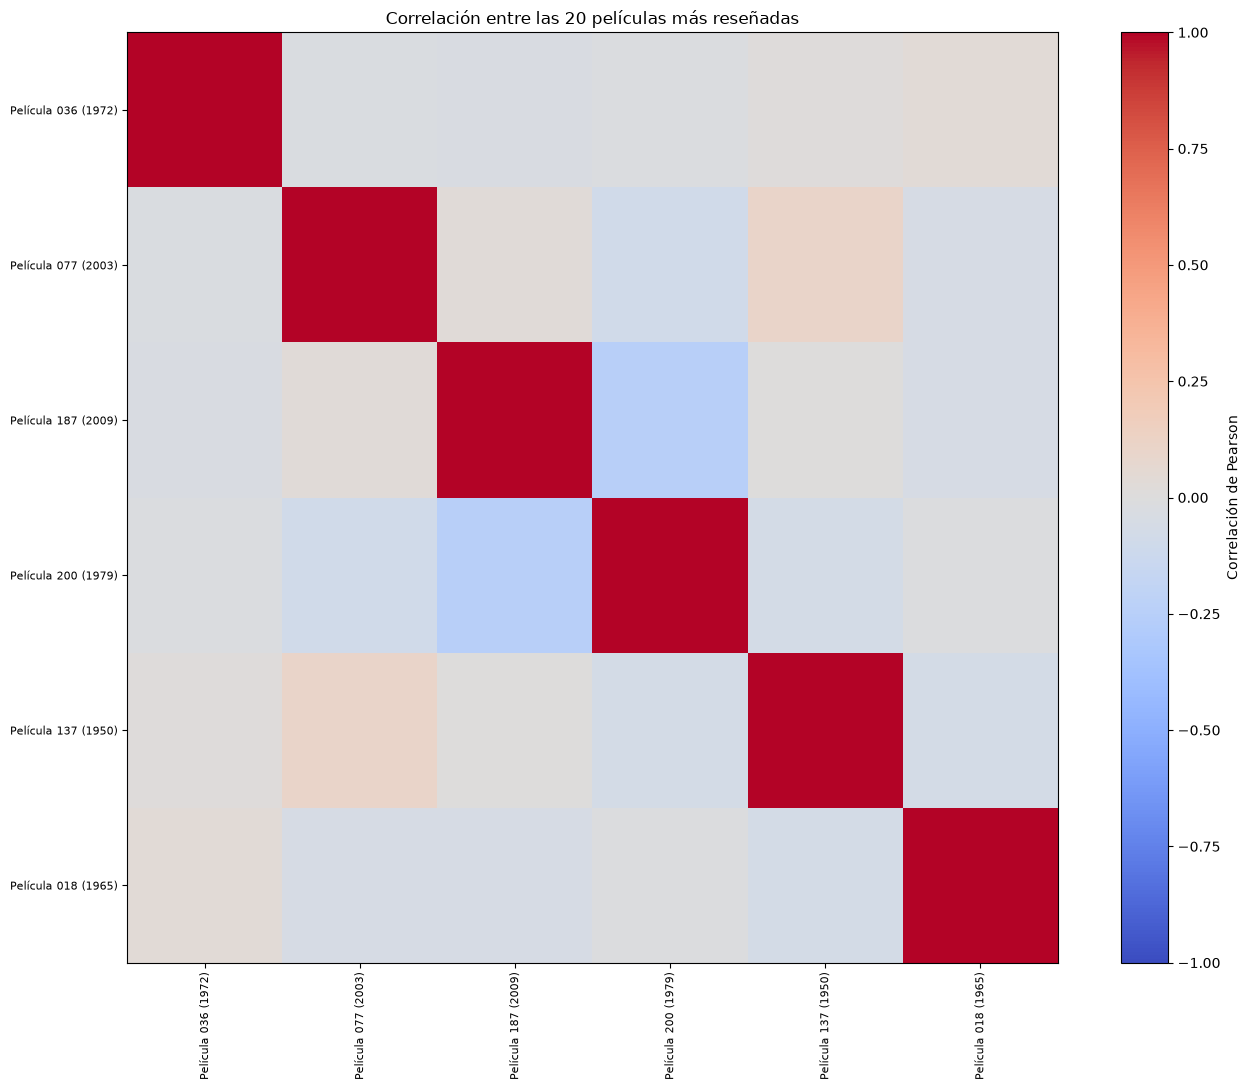

In [10]:
# TODO: heatmap (imshow) de unas 20 películas
# rutas.guardar_figura(fig, "03_heatmap_peliculas")

peliculas_heatmap = gustos.notna().sum().sort_values(
    ascending=False
).head(20).index

# Obtener sus correlaciones
correlaciones_heatmap = correlaciones.loc[
    peliculas_heatmap,
    peliculas_heatmap
]

# Recuperar los títulos
titulos = movies.set_index("movieId").loc[
    peliculas_heatmap, "title"
]

# Crear el gráfico
fig, ax = plt.subplots(figsize=(14, 11))

imagen = ax.imshow(
    correlaciones_heatmap,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(titulos)))
ax.set_yticks(range(len(titulos)))

ax.set_xticklabels(titulos, rotation=90, fontsize=8)
ax.set_yticklabels(titulos, fontsize=8)

ax.set_title("Correlación entre las 20 películas más reseñadas")
fig.colorbar(imagen, ax=ax, label="Correlación de Pearson")

plt.tight_layout()

# Guardar figura
rutas.guardar_figura(fig, "03_heatmap_peliculas")

plt.show()

> **Interpretación**
> - *Qué muestra:* …
> - *Por qué es relevante:* …
> - *Limitaciones:* …

## 5. Probabilidades condicionales

La correlación es simétrica; "si le gusta X, le gusta Y" no lo es.

In [11]:
# TODO: para los 5 mejores pares: crosstab normalize='index' → P(le gusta Y | le gusta X) contra P(le gusta Y)
mejores_pares = pares_correlacion.head(5)

resultados = []

for _, par in mejores_pares.iterrows():

    pelicula_x = par["movieId_1"]
    pelicula_y = par["movieId_2"]

    # Obtener los gustos de ambas películas
    gustos_par = gustos[[pelicula_x, pelicula_y]].dropna()

    # Tabla de contingencia normalizada por filas
    tabla = pd.crosstab(
        gustos_par[pelicula_x],
        gustos_par[pelicula_y],
        normalize="index"
    )

    # Probabilidad condicionada y probabilidad general
    p_y_dado_x = tabla.loc[1.0, 1.0]
    p_y_general = gustos[pelicula_y].mean()

    resultados.append({
        "pelicula_X": movies.set_index("movieId").loc[pelicula_x, "title"],
        "pelicula_Y": movies.set_index("movieId").loc[pelicula_y, "title"],
        "P(Y|X)": p_y_dado_x,
        "P(Y)": p_y_general,
        "diferencia": p_y_dado_x - p_y_general
    })

comparacion_probabilidades = pd.DataFrame(resultados)

comparacion_probabilidades

,pelicula_X,pelicula_Y,P(Y|X),P(Y),diferencia
0,Película 077 (2003),Película 137 (1950),0.529412,0.471154,0.058258
1,Película 018 (1965),Película 036 (1972),0.471698,0.478992,-0.007293
2,Película 187 (2009),Película 077 (2003),0.511628,0.491379,0.020249
3,Película 036 (1972),Película 137 (1950),0.479167,0.471154,0.008013
4,Película 187 (2009),Película 137 (1950),0.486486,0.471154,0.015333


## 6. Conclusión y limitaciones

…